In [20]:
import tensorflow as tf
from tensorflow import keras
from keras import layers
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.model_selection import train_test_split

In [21]:
train = pd.read_csv("cifar-10.csv")
train, test= train_test_split(train, test_size=0.2, random_state=42)

In [22]:
y_train = train.pop("label")
y_test = test.pop("label")
x_train = train.to_numpy("float32") /255
x_test = test.to_numpy("float32") /255


In [23]:
m = keras.Sequential([layers.Input((3072,)),
                      layers.Dense(256, activation='relu'),
                      layers.Dense(10, activation='softmax')])

In [24]:
m.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
h = m.fit(x_train, y_train, epochs=20, batch_size = 128, validation_split=0.1)

Epoch 1/20
282/282 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.3041 - loss: 1.9788 - val_accuracy: 0.3113 - val_loss: 1.8899
Epoch 2/20
282/282 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.3745 - loss: 1.7644 - val_accuracy: 0.3532 - val_loss: 1.7773
Epoch 3/20
282/282 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.4014 - loss: 1.6882 - val_accuracy: 0.4085 - val_loss: 1.6831
Epoch 4/20
282/282 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.4195 - loss: 1.6462 - val_accuracy: 0.4112 - val_loss: 1.6725
Epoch 5/20
282/282 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.4318 - loss: 1.6063 - val_accuracy: 0.4112 - val_loss: 1.6506
Epoch 6/20
282/282 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.4423 - loss: 1.5755 - val_accuracy: 0.4187 - val_loss: 1.6155
Epoch 7/20
282/282 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.4534 - loss: 1.5504 - val_accuracy: 0.4325 - val_loss: 1.5847
Epoch 8/20
282/282 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.4629 - loss: 1.5234 - val_accuracy: 0.

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.4810 - loss: 1.4752
Test loss, accuracy: [1.475157380104065, 0.48100000619888306]


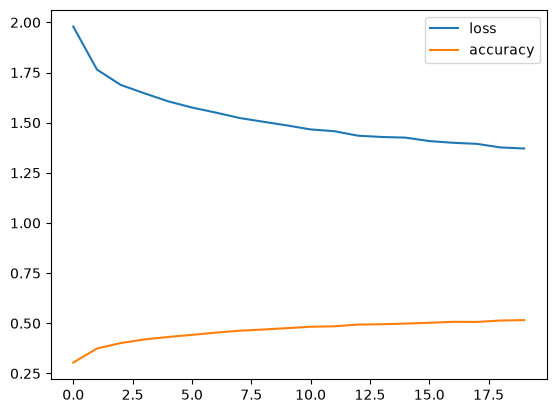

In [26]:
print('Test loss, accuracy:', m.evaluate(x_test, y_test))
for k in ['loss', 'accuracy']: plt.plot(h.history[k], label=k)
plt.legend(); plt.show()